In [197]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, ElasticNet, ElasticNetCV
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import root_mean_squared_log_error, r2_score

In [198]:
df_train = pd.read_csv('train.csv')
df_train.head()

,id,season_code,flag_holiday,flag_working,category_weather,feature_temp,feature_feel_temp,feature_humidity,feature_wind,demand,Year,Hour,Day_of_Week,Month
0,1,4,0,1,2,0.26,0.2576,0.70,0.1642,34,2012,2,4,11
1,2,4,0,1,1,0.58,0.5455,0.64,0.0000,341,2012,11,3,10
2,3,4,0,0,3,0.22,0.1970,0.93,0.3284,67,2011,17,6,10
3,4,1,0,1,2,0.36,0.3636,0.66,0.1045,40,2011,1,3,12
4,5,1,0,0,2,0.04,0.0606,0.41,0.1642,96,2011,10,6,1


In [199]:
df_train.sample(10)

,id,season_code,flag_holiday,flag_working,category_weather,feature_temp,feature_feel_temp,feature_humidity,feature_wind,demand,Year,Hour,Day_of_Week,Month
4698,4699,3,0,1,1,0.66,0.6212,0.50,0.3284,704,2012,7,3,7
7729,7730,1,0,0,1,0.26,0.2273,0.60,0.3582,28,2011,4,0,2
8759,8760,4,0,1,1,0.32,0.3485,0.93,0.0000,28,2011,2,1,11
3423,3424,2,0,1,1,0.66,0.6212,0.61,0.2537,237,2011,21,1,4
4746,4747,2,0,1,1,0.64,0.6212,0.41,0.1343,631,2012,16,3,6
4519,4520,4,0,1,1,0.36,0.3485,0.34,0.1642,349,2012,14,4,12
1986,1987,4,0,1,1,0.62,0.6212,0.53,0.3582,470,2012,13,4,10
4960,4961,3,0,1,1,0.70,0.6667,NaN,0.2239,497,2011,20,4,6
4008,4009,3,0,1,1,0.76,0.7424,0.75,0.0896,154,2011,6,5,7
9251,9252,3,0,0,1,0.72,0.6970,0.79,0.1940,144,2011,8,0,8


In [200]:
df_train.shape

(12165, 14)

In [201]:
df_train.columns

Index(['id', 'season_code', 'flag_holiday', 'flag_working', 'category_weather',
       'feature_temp', 'feature_feel_temp', 'feature_humidity', 'feature_wind',
       'demand', 'Year', 'Hour', 'Day_of_Week', 'Month'],
      dtype='str')

In [202]:
df_train.dtypes

id                     int64
season_code            int64
flag_holiday           int64
flag_working           int64
category_weather       int64
feature_temp         float64
feature_feel_temp    float64
feature_humidity     float64
feature_wind         float64
demand                 int64
Year                   int64
Hour                   int64
Day_of_Week            int64
Month                  int64
dtype: object

In [203]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 12165 entries, 0 to 12164
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 12165 non-null  int64  
 1   season_code        12165 non-null  int64  
 2   flag_holiday       12165 non-null  int64  
 3   flag_working       12165 non-null  int64  
 4   category_weather   12165 non-null  int64  
 5   feature_temp       12165 non-null  float64
 6   feature_feel_temp  12165 non-null  float64
 7   feature_humidity   11557 non-null  float64
 8   feature_wind       11557 non-null  float64
 9   demand             12165 non-null  int64  
 10  Year               12165 non-null  int64  
 11  Hour               12165 non-null  int64  
 12  Day_of_Week        12165 non-null  int64  
 13  Month              12165 non-null  int64  
dtypes: float64(4), int64(10)
memory usage: 1.3 MB


In [204]:
df_train.describe()

,id,season_code,flag_holiday,flag_working,category_weather,feature_temp,feature_feel_temp,feature_humidity,feature_wind,demand,Year,Hour,Day_of_Week,Month
count,12165.000000,12165.000000,12165.000000,12165.000000,12165.000000,12165.000000,12165.000000,11557.000000,11557.000000,12165.000000,12165.000000,12165.000000,12165.000000,12165.000000
mean,6083.000000,2.500534,0.028442,0.685656,1.425072,0.497197,0.475919,0.626863,0.189611,279.223263,2011.501192,11.573120,3.002466,6.541060
std,3511.877347,1.109777,0.166239,0.464273,0.637076,0.192414,0.171508,0.193058,0.121757,241.989716,0.500019,6.907753,2.000697,3.439269
min,1.000000,1.000000,0.000000,0.000000,1.000000,0.020000,0.015200,0.000000,0.000000,26.000000,2011.000000,0.000000,0.000000,1.000000
25%,3042.000000,2.000000,0.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,79.000000,2011.000000,6.000000,1.000000,4.000000
50%,6083.000000,3.000000,0.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,218.000000,2012.000000,12.000000,3.000000,7.000000
75%,9124.000000,3.000000,0.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,402.000000,2012.000000,18.000000,5.000000,10.000000
max,12165.000000,4.000000,1.000000,1.000000,4.000000,0.980000,1.000000,1.000000,0.850700,1334.000000,2012.000000,23.000000,6.000000,12.000000


In [205]:
df_train.isnull().sum()

id                     0
season_code            0
flag_holiday           0
flag_working           0
category_weather       0
feature_temp           0
feature_feel_temp      0
feature_humidity     608
feature_wind         608
demand                 0
Year                   0
Hour                   0
Day_of_Week            0
Month                  0
dtype: int64

In [206]:
df_train.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
12160    False
12161    False
12162    False
12163    False
12164    False
Length: 12165, dtype: bool

In [207]:
df_train.duplicated().sum()

np.int64(0)

In [208]:
df_train.nunique()

id                   12165
season_code              4
flag_holiday             2
flag_working             2
category_weather         4
feature_temp            49
feature_feel_temp       64
feature_humidity        87
feature_wind            29
demand                 830
Year                     2
Hour                    24
Day_of_Week              7
Month                   12
dtype: int64

In [209]:
df_test = pd.read_csv("test.csv")
df_test.head()

,id,season_code,flag_holiday,flag_working,category_weather,feature_temp,feature_feel_temp,feature_humidity,feature_wind,Year,Hour,Day_of_Week,Month
0,12166,3,0,1,2,0.62,0.5909,0.78,0.1642,2011,6,1,6
1,12167,2,0,1,1,0.70,0.6667,0.79,NaN,2012,0,2,5
2,12168,4,0,1,1,0.32,0.3030,0.45,0.2537,2011,14,4,12
3,12169,1,1,0,2,0.16,0.1515,0.55,0.1940,2011,11,1,1
4,12170,1,0,1,1,0.52,0.5000,0.63,0.0896,2012,1,3,3


In [210]:
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 5214 entries, 0 to 5213
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5214 non-null   int64  
 1   season_code        5214 non-null   int64  
 2   flag_holiday       5214 non-null   int64  
 3   flag_working       5214 non-null   int64  
 4   category_weather   5214 non-null   int64  
 5   feature_temp       5214 non-null   float64
 6   feature_feel_temp  5214 non-null   float64
 7   feature_humidity   4953 non-null   float64
 8   feature_wind       4953 non-null   float64
 9   Year               5214 non-null   int64  
 10  Hour               5214 non-null   int64  
 11  Day_of_Week        5214 non-null   int64  
 12  Month              5214 non-null   int64  
dtypes: float64(4), int64(9)
memory usage: 529.7 KB


In [211]:
df_test.isnull().sum()

id                     0
season_code            0
flag_holiday           0
flag_working           0
category_weather       0
feature_temp           0
feature_feel_temp      0
feature_humidity     261
feature_wind         261
Year                   0
Hour                   0
Day_of_Week            0
Month                  0
dtype: int64

In [212]:
dependence = ['season_code', 'category_weather']
cols_to_impute = ['feature_wind', 'feature_humidity']

for col in cols_to_impute:
    df_train[col] = df_train[col].fillna(
        df_train.groupby(dependence)[col].transform('median')
    )
    df_train[col] = df_train[col].fillna(df_train[col].median())

group_medians = (
    df_train.groupby(dependence)[cols_to_impute]
    .median()
    .reset_index()
)

df_test = df_test.merge(
    group_medians,
    on=dependence,
    how='left',
    suffixes=('', '_median')
)

for col in cols_to_impute:
    df_test[col] = df_test[col].fillna(df_test[f'{col}_median'])
    df_test[col] = df_test[col].fillna(df_train[col].median())

df_test.drop(
    columns=[f'{col}_median' for col in cols_to_impute],
    inplace=True
)

In [213]:
df_train.isnull().sum()

id                   0
season_code          0
flag_holiday         0
flag_working         0
category_weather     0
feature_temp         0
feature_feel_temp    0
feature_humidity     0
feature_wind         0
demand               0
Year                 0
Hour                 0
Day_of_Week          0
Month                0
dtype: int64

In [214]:
df_test.isnull().sum()

id                   0
season_code          0
flag_holiday         0
flag_working         0
category_weather     0
feature_temp         0
feature_feel_temp    0
feature_humidity     0
feature_wind         0
Year                 0
Hour                 0
Day_of_Week          0
Month                0
dtype: int64

In [215]:
# sns.pairplot(df_train.drop(columns = 'id'))

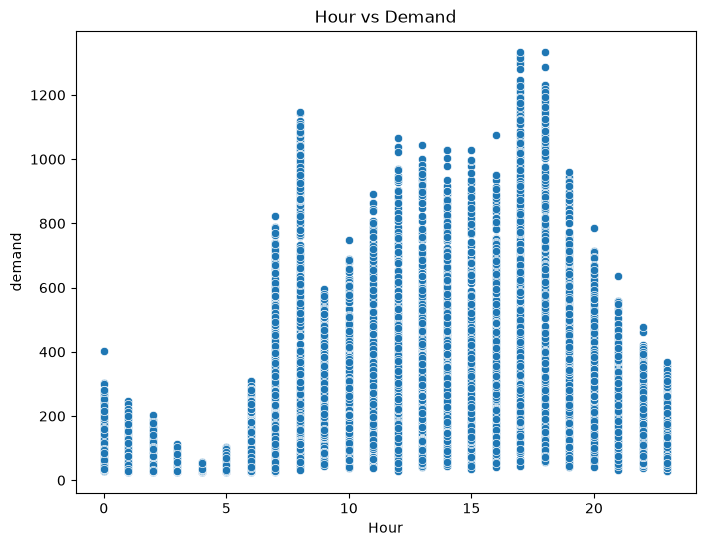

In [216]:
plt.figure(figsize=(8,6))
sns.scatterplot(x='Hour',y='demand',data=df_train)
plt.title("Hour vs Demand")
plt.show()

In [217]:
df_train['hour_sin'] = np.sin(2 * np.pi * df_train['Hour'] / 24.0)
df_train['hour_cos'] = np.cos(2 * np.pi * df_train['Hour'] / 24.0)
df_train['month_sin'] = np.sin(2 * np.pi * df_train['Month'] / 12.0)
df_train['month_cos'] = np.cos(2 * np.pi * df_train['Month'] / 12.0)

df_test['hour_sin'] = np.sin(2 * np.pi * df_test['Hour'] / 24.0)
df_test['hour_cos'] = np.cos(2 * np.pi * df_test['Hour'] / 24.0)
df_test['month_sin'] = np.sin(2 * np.pi * df_test['Month'] / 12.0)
df_test['month_cos'] = np.cos(2 * np.pi * df_test['Month'] / 12.0)

In [218]:
df_train["dow_sin"] = np.sin(2*np.pi*df_train.Day_of_Week/7)
df_train["dow_cos"] = np.cos(2*np.pi*df_train.Day_of_Week/7)

df_test["dow_sin"] = np.sin(2*np.pi*df_test.Day_of_Week/7)
df_test["dow_cos"] = np.cos(2*np.pi*df_test.Day_of_Week/7)

In [219]:
df_train['is_peak'] = df_train['Hour'].isin([7,8,9,17,18,19]).astype(int)
df_train['is_weekend'] = (df_train['Day_of_Week'].isin([0,6])).astype(int)

df_test['is_peak'] = df_test['Hour'].isin([7,8,9,17,18,19]).astype(int)
df_test['is_weekend'] = (df_test['Day_of_Week'].isin([0,6])).astype(int)


In [220]:
df_train["rush_bad_weather"] = (df_train["Hour"].isin([7,8,9,17,18,19]).astype(int)*df_train["category_weather"])
df_test["rush_bad_weather"] = (df_test["Hour"].isin([7,8,9,17,18,19]).astype(int)*df_test["category_weather"])

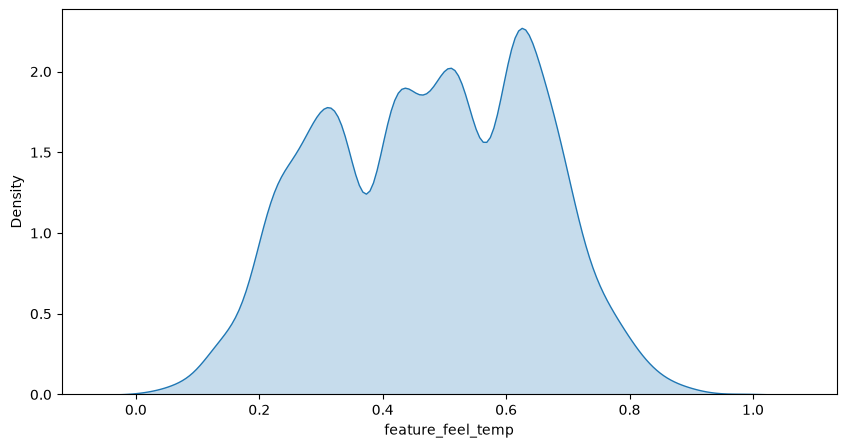

In [221]:
plt.figure(figsize=(10,5))
sns.kdeplot(df_train['feature_feel_temp'],fill=True)
plt.show()

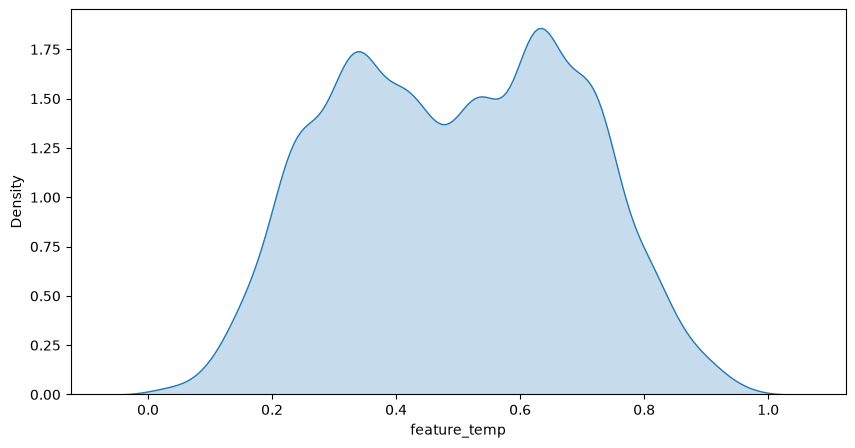

In [222]:
plt.figure(figsize=(10,5))
sns.kdeplot(df_train['feature_temp'],fill=True)
plt.show()

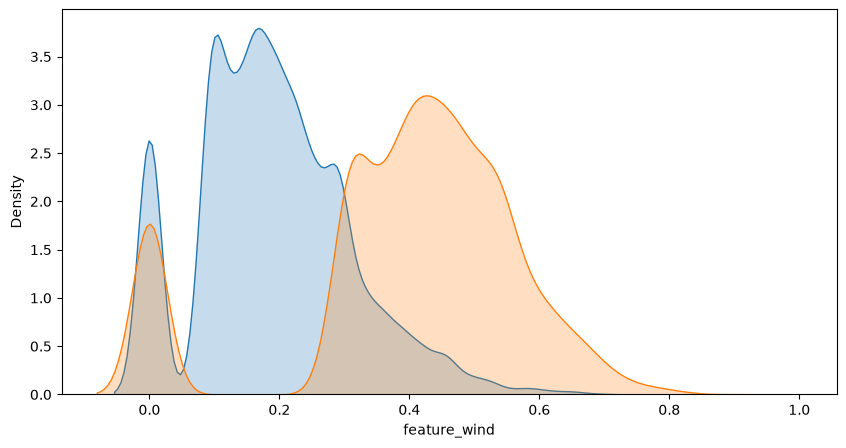

In [223]:
plt.figure(figsize=(10,5))
sns.kdeplot(df_train['feature_wind'],fill=True)
sns.kdeplot(np.sqrt(df_train['feature_wind']),fill=True)

plt.show()

In [224]:
df_train['feature_wind'] = np.sqrt(df_train['feature_wind'])
df_test['feature_wind'] = np.sqrt(df_test['feature_wind'])

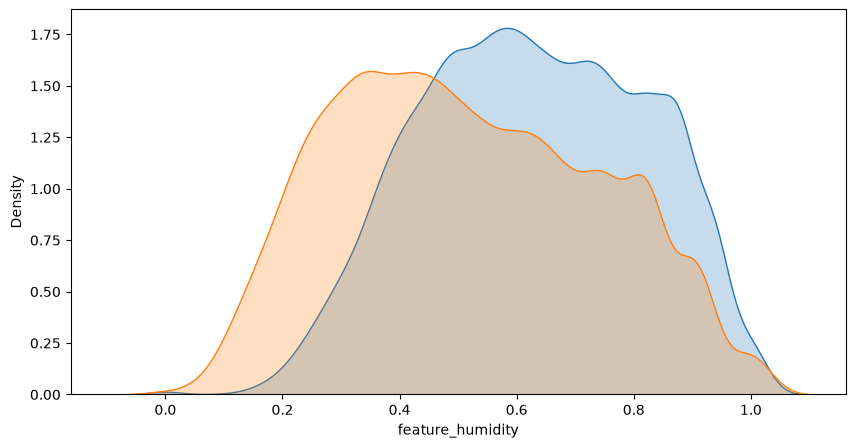

In [225]:
plt.figure(figsize=(10,5))
sns.kdeplot(df_train['feature_humidity'],fill=True)
sns.kdeplot(np.power(df_train['feature_humidity'], 1.5),fill=True)
plt.show()

In [226]:
df_train['feature_humidity'] = np.power(df_train['feature_humidity'], 1.5)
df_test['feature_humidity'] = np.power(df_test['feature_humidity'], 1.5)

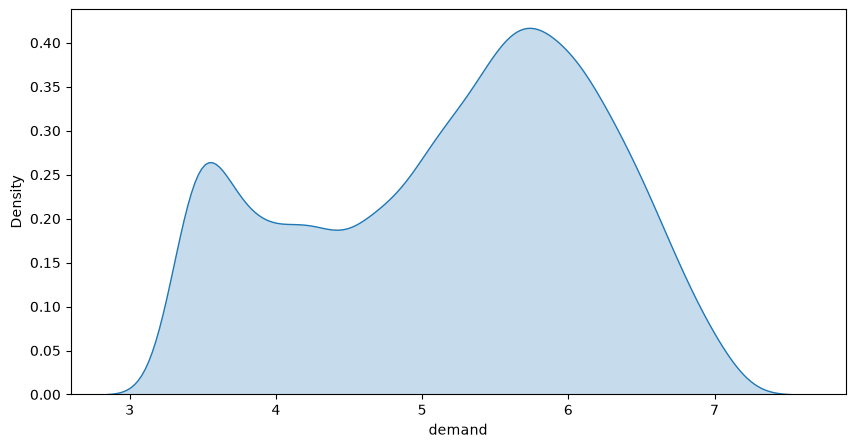

In [227]:
plt.figure(figsize=(10,5))
sns.kdeplot(np.log1p(df_train['demand']),fill=True)

plt.show()

In [228]:
ohe_cols = ['season_code', 'category_weather', 'Day_of_Week', 'Hour', 'Year', 'Month']

for col in ohe_cols:
    if col in df_train.columns:
        df_train[col] = df_train[col].astype(str)
        df_test[col] = df_test[col].astype(str)

df_train = pd.get_dummies(df_train, columns=ohe_cols, drop_first=True, dtype=int)
df_test = pd.get_dummies(df_test, columns=ohe_cols, drop_first=True, dtype=int)


In [229]:
df_train.columns

Index(['id', 'flag_holiday', 'flag_working', 'feature_temp',
       'feature_feel_temp', 'feature_humidity', 'feature_wind', 'demand',
       'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'dow_sin', 'dow_cos',
       'is_peak', 'is_weekend', 'rush_bad_weather', 'season_code_2',
       'season_code_3', 'season_code_4', 'category_weather_2',
       'category_weather_3', 'category_weather_4', 'Day_of_Week_1',
       'Day_of_Week_2', 'Day_of_Week_3', 'Day_of_Week_4', 'Day_of_Week_5',
       'Day_of_Week_6', 'Hour_1', 'Hour_10', 'Hour_11', 'Hour_12', 'Hour_13',
       'Hour_14', 'Hour_15', 'Hour_16', 'Hour_17', 'Hour_18', 'Hour_19',
       'Hour_2', 'Hour_20', 'Hour_21', 'Hour_22', 'Hour_23', 'Hour_3',
       'Hour_4', 'Hour_5', 'Hour_6', 'Hour_7', 'Hour_8', 'Hour_9', 'Year_2012',
       'Month_10', 'Month_11', 'Month_12', 'Month_2', 'Month_3', 'Month_4',
       'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_9'],
      dtype='str')

In [230]:
df_train.head()

,id,flag_holiday,flag_working,feature_temp,feature_feel_temp,feature_humidity,feature_wind,demand,hour_sin,hour_cos,...,Month_11,Month_12,Month_2,Month_3,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9
0,1,0,1,0.26,0.2576,0.585662,0.405216,34,0.500000,0.866025,...,1,0,0,0,0,0,0,0,0,0
1,2,0,1,0.58,0.5455,0.512000,0.000000,341,0.258819,-0.965926,...,0,0,0,0,0,0,0,0,0,0
2,3,0,0,0.22,0.1970,0.896860,0.573062,67,-0.965926,-0.258819,...,0,0,0,0,0,0,0,0,0,0
3,4,0,1,0.36,0.3636,0.536187,0.323265,40,0.258819,0.965926,...,0,1,0,0,0,0,0,0,0,0
4,5,0,0,0.04,0.0606,0.262528,0.405216,96,0.500000,-0.866025,...,0,0,0,0,0,0,0,0,0,0


In [231]:
df_test.head()

,id,flag_holiday,flag_working,feature_temp,feature_feel_temp,feature_humidity,feature_wind,hour_sin,hour_cos,month_sin,...,Month_11,Month_12,Month_2,Month_3,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9
0,12166,0,1,0.62,0.5909,0.688877,0.405216,1.000000,6.123234e-17,1.224647e-16,...,0,0,0,0,0,0,1,0,0,0
1,12167,0,1,0.70,0.6667,0.702167,0.440454,0.000000,1.000000e+00,5.000000e-01,...,0,0,0,0,0,1,0,0,0,0
2,12168,0,1,0.32,0.3030,0.301869,0.503686,-0.500000,-8.660254e-01,-2.449294e-16,...,0,1,0,0,0,0,0,0,0,0
3,12169,1,0,0.16,0.1515,0.407891,0.440454,0.258819,-9.659258e-01,5.000000e-01,...,0,0,0,0,0,0,0,0,0,0
4,12170,0,1,0.52,0.5000,0.500047,0.299333,0.258819,9.659258e-01,1.000000e+00,...,0,0,0,1,0,0,0,0,0,0


In [232]:
numeric_df = df_train.drop(columns='id').select_dtypes(include=np.number)
corr = numeric_df.corr()
corr

,flag_holiday,flag_working,feature_temp,feature_feel_temp,feature_humidity,feature_wind,demand,hour_sin,hour_cos,month_sin,...,Month_11,Month_12,Month_2,Month_3,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9
flag_holiday,1.000000,-0.252696,-0.032358,-0.035302,-0.010322,-0.004081,-0.036413,-0.001239,0.002688,-0.008113,...,0.055820,0.013629,0.003271,-0.052148,0.006840,0.006474,-0.051317,0.003864,-0.051623,0.009695
flag_working,-0.252696,1.000000,0.048867,0.047249,0.017249,-0.011838,0.024296,0.004307,-0.001660,0.002182,...,-0.010618,-0.012658,0.003833,0.027322,-0.015638,0.003434,0.023552,-0.016134,0.042937,-0.010591
feature_temp,-0.032358,0.048867,1.000000,0.988547,-0.064564,-0.008644,0.400890,-0.181591,-0.131321,-0.450421,...,-0.203404,-0.271841,-0.295453,-0.170727,-0.041338,0.155346,0.292721,0.412641,0.333158,0.188394
feature_feel_temp,-0.035302,0.047249,0.988547,1.000000,-0.049806,-0.046653,0.397118,-0.174685,-0.124425,-0.442252,...,-0.193605,-0.264378,-0.294119,-0.169479,-0.032294,0.159633,0.285042,0.408826,0.311798,0.182142
feature_humidity,-0.010322,0.017249,-0.064564,-0.049806,1.000000,-0.219311,-0.318492,0.345799,0.262666,-0.140186,...,-0.006230,0.060133,-0.098238,-0.048544,-0.048088,0.094585,-0.074406,-0.053858,0.006305,0.137208
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Month_5,0.006474,0.003434,0.155346,0.159633,0.094585,0.006605,0.042711,0.008406,0.003658,0.218605,...,-0.091762,-0.092648,-0.088966,-0.092796,-0.090720,1.000000,-0.091316,-0.093480,-0.091861,-0.092992
Month_6,-0.051317,0.023552,0.292721,0.285042,-0.074406,0.006676,0.078620,-0.005477,-0.001789,0.003099,...,-0.090395,-0.091268,-0.087641,-0.091413,-0.089369,-0.091316,1.000000,-0.092088,-0.090492,-0.091606
Month_7,0.003864,-0.016134,0.412641,0.408826,-0.053858,-0.047432,0.074340,0.010310,-0.000520,-0.214106,...,-0.092537,-0.093431,-0.089718,-0.093579,-0.091487,-0.093480,-0.092088,1.000000,-0.092637,-0.093777
Month_8,-0.051623,0.042937,0.333158,0.311798,0.006305,-0.050026,0.085519,0.004129,-0.003977,-0.366698,...,-0.090934,-0.091812,-0.088163,-0.091958,-0.089901,-0.091861,-0.090492,-0.092637,1.000000,-0.092152


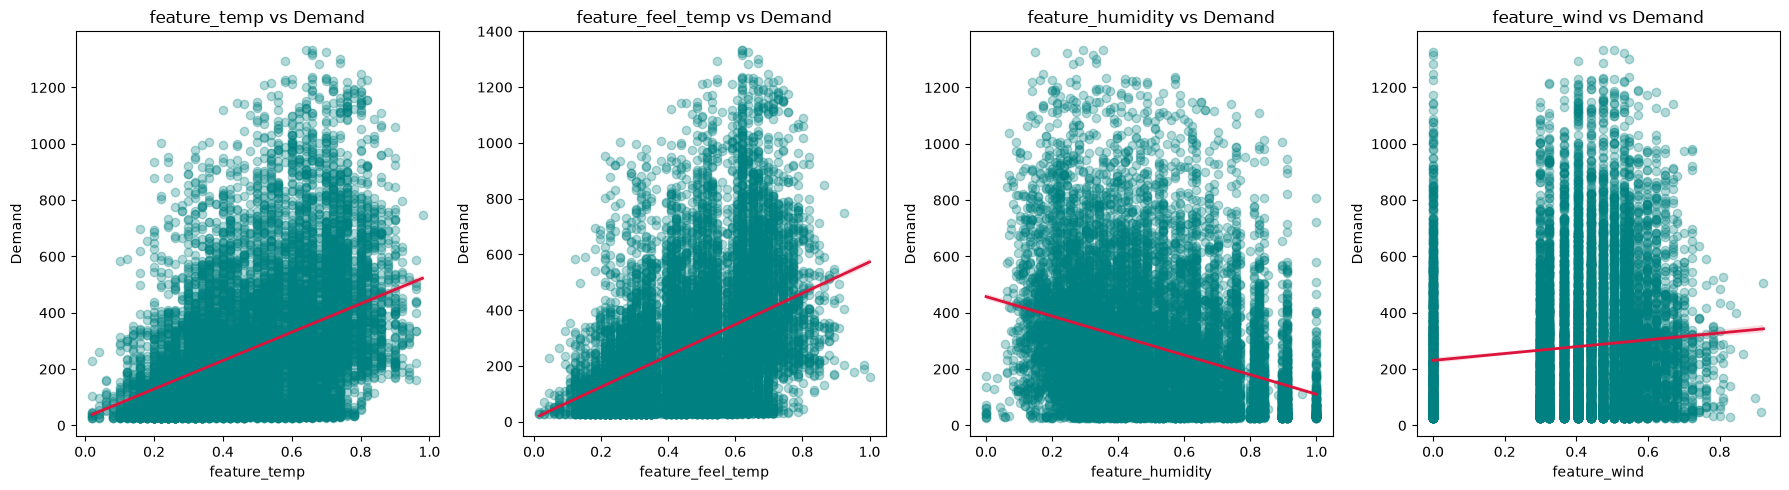

In [233]:
features = ["feature_temp", "feature_feel_temp", "feature_humidity", "feature_wind"]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for i, col in enumerate(features):
    sns.regplot(
        data=df_train,
        x=col,
        y="demand",
        ax=axes[i],
        scatter_kws={"alpha": 0.3, "color": "teal"},
        line_kws={"color": "crimson", "linewidth": 2},
    )
    axes[i].set_title(f"{col} vs Demand")
    axes[i].set_ylabel("Demand")
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

In [234]:
df_train = df_train.drop(columns = 'feature_temp')
df_test = df_test.drop(columns = 'feature_temp')

In [235]:
df_train['Hour_7_Workday'] = df_train['Hour_7'] * df_train['flag_working']
df_train['Hour_8_Workday'] = df_train['Hour_8'] * df_train['flag_working']
df_train['Hour_9_Workday'] = df_train['Hour_9'] * df_train['flag_working']
df_train['Hour_17_Workday'] = df_train['Hour_17'] * df_train['flag_working']
df_train['Hour_18_Workday'] = df_train['Hour_18'] * df_train['flag_working']
df_train['Hour_19_Workday'] = df_train['Hour_19'] * df_train['flag_working']

df_test['Hour_7_Workday'] = df_test['Hour_7'] * df_test['flag_working']
df_test['Hour_8_Workday'] = df_test['Hour_8'] * df_test['flag_working']
df_test['Hour_9_Workday'] = df_test['Hour_9'] * df_test['flag_working']
df_test['Hour_17_Workday'] = df_test['Hour_17'] * df_test['flag_working']
df_test['Hour_18_Workday'] = df_test['Hour_18'] * df_test['flag_working']
df_test['Hour_19_Workday'] = df_test['Hour_19'] * df_test['flag_working']

In [236]:
df_train['wind_workday'] = df_train['feature_wind'] * df_train['flag_working']
df_test['wind_workday'] = df_test['feature_wind'] * df_test['flag_working']

df_train['humidity_workday'] = df_train['feature_humidity'] * df_train['flag_working']
df_test['humidity_workday'] = df_test['feature_humidity'] * df_test['flag_working']

In [237]:
df_train.columns

Index(['id', 'flag_holiday', 'flag_working', 'feature_feel_temp',
       'feature_humidity', 'feature_wind', 'demand', 'hour_sin', 'hour_cos',
       'month_sin', 'month_cos', 'dow_sin', 'dow_cos', 'is_peak', 'is_weekend',
       'rush_bad_weather', 'season_code_2', 'season_code_3', 'season_code_4',
       'category_weather_2', 'category_weather_3', 'category_weather_4',
       'Day_of_Week_1', 'Day_of_Week_2', 'Day_of_Week_3', 'Day_of_Week_4',
       'Day_of_Week_5', 'Day_of_Week_6', 'Hour_1', 'Hour_10', 'Hour_11',
       'Hour_12', 'Hour_13', 'Hour_14', 'Hour_15', 'Hour_16', 'Hour_17',
       'Hour_18', 'Hour_19', 'Hour_2', 'Hour_20', 'Hour_21', 'Hour_22',
       'Hour_23', 'Hour_3', 'Hour_4', 'Hour_5', 'Hour_6', 'Hour_7', 'Hour_8',
       'Hour_9', 'Year_2012', 'Month_10', 'Month_11', 'Month_12', 'Month_2',
       'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8',
       'Month_9', 'Hour_7_Workday', 'Hour_8_Workday', 'Hour_9_Workday',
       'Hour_17_Workday', 'Hour_1

In [238]:
df_train.head()

,id,flag_holiday,flag_working,feature_feel_temp,feature_humidity,feature_wind,demand,hour_sin,hour_cos,month_sin,...,Month_8,Month_9,Hour_7_Workday,Hour_8_Workday,Hour_9_Workday,Hour_17_Workday,Hour_18_Workday,Hour_19_Workday,wind_workday,humidity_workday
0,1,0,1,0.2576,0.585662,0.405216,34,0.500000,0.866025,-5.000000e-01,...,0,0,0,0,0,0,0,0,0.405216,0.585662
1,2,0,1,0.5455,0.512000,0.000000,341,0.258819,-0.965926,-8.660254e-01,...,0,0,0,0,0,0,0,0,0.000000,0.512000
2,3,0,0,0.1970,0.896860,0.573062,67,-0.965926,-0.258819,-8.660254e-01,...,0,0,0,0,0,0,0,0,0.000000,0.000000
3,4,0,1,0.3636,0.536187,0.323265,40,0.258819,0.965926,-2.449294e-16,...,0,0,0,0,0,0,0,0,0.323265,0.536187
4,5,0,0,0.0606,0.262528,0.405216,96,0.500000,-0.866025,5.000000e-01,...,0,0,0,0,0,0,0,0,0.000000,0.000000


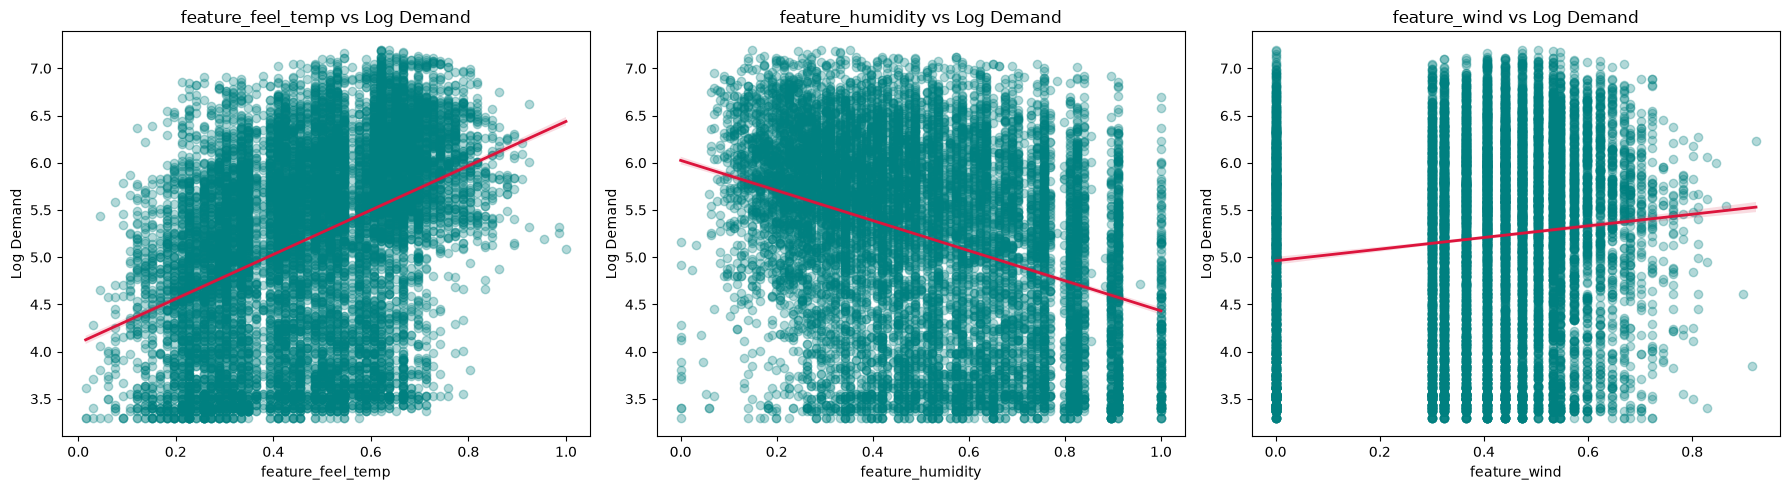

In [239]:
features = ["feature_feel_temp", "feature_humidity", "feature_wind"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(features):
    sns.regplot(
        data=df_train,
        x=col,
        y=np.log1p(df_train["demand"]),
        ax=axes[i],
        scatter_kws={"alpha": 0.3, "color": "teal"},
        line_kws={"color": "crimson", "linewidth": 2},
    )
    axes[i].set_title(f"{col} vs Log Demand")
    axes[i].set_ylabel("Log Demand")
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

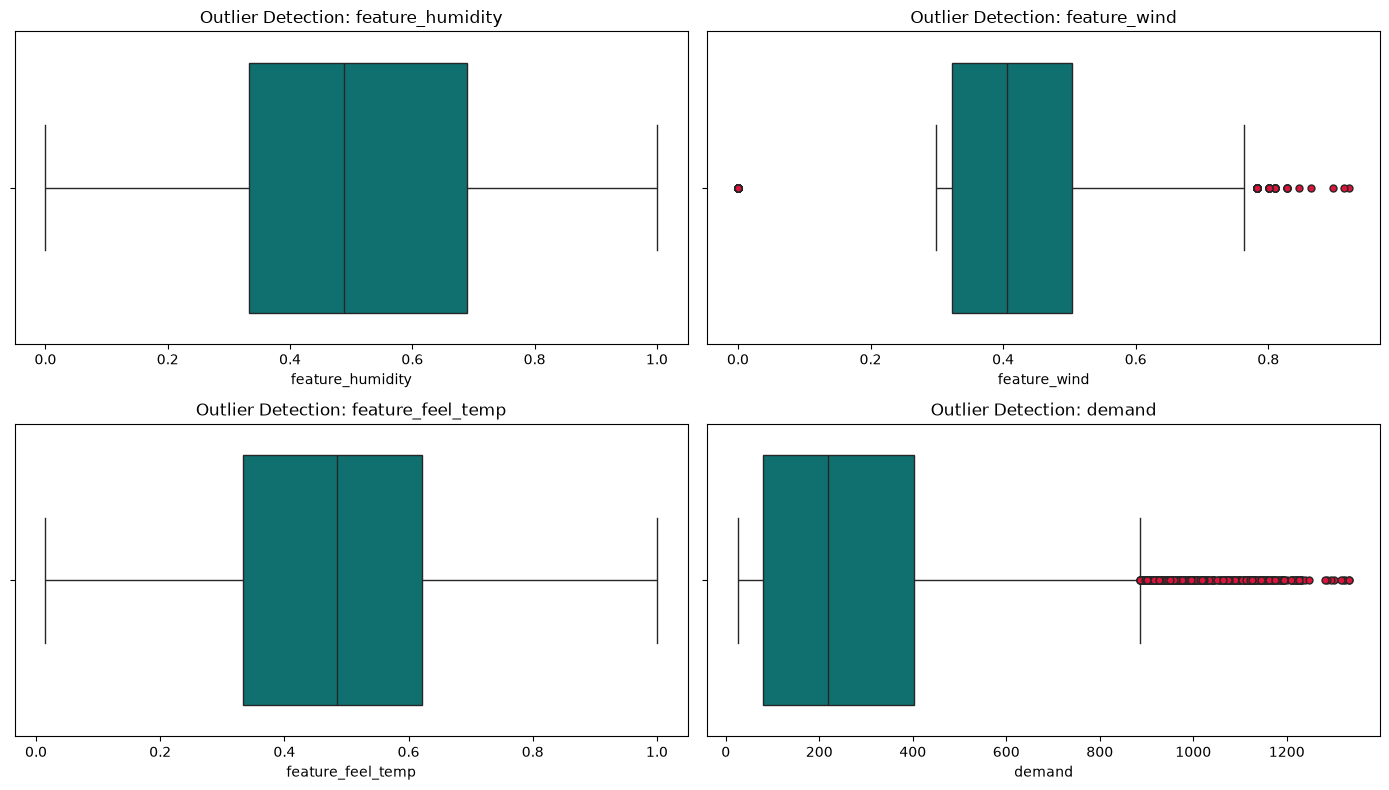

In [240]:
import math
outlier_check_cols = [
    "feature_humidity",
    "feature_wind",
    "feature_feel_temp",
    "demand",
]

num_features = len(outlier_check_cols)
num_cols = 2
num_rows = math.ceil(num_features / num_cols)

fig, axes = plt.subplots(num_rows, num_cols, figsize=(14, 4 * num_rows))
axes = axes.flatten()

for i, col in enumerate(outlier_check_cols):
    if col in df_train.columns:
        sns.boxplot(
            data=df_train,
            x=col,
            ax=axes[i],
            color="teal",
            flierprops={
                "markerfacecolor": "crimson",
                "marker": "o",
                "markersize": 5,
            },
        )
        axes[i].set_title(f"Outlier Detection: {col}")
        axes[i].set_xlabel(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [241]:
lower_wind_bound = 0.15
higher_wind_bound = 0.75

df_train["feature_wind"] = df_train["feature_wind"].clip(
    lower = lower_wind_bound,
    upper = higher_wind_bound
)
df_test["feature_wind"] = df_test["feature_wind"].clip(
    lower = lower_wind_bound,
    upper = higher_wind_bound
)

<Axes: xlabel='feature_wind'>

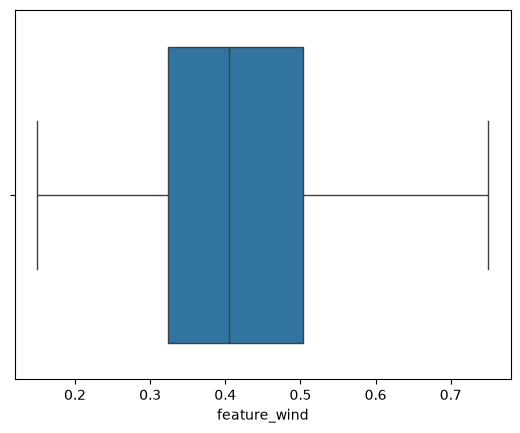

In [242]:
sns.boxplot(x='feature_wind', data=df_train)

In [243]:
new_order = [col for col in df_train.columns if col != 'demand'] + ['demand']
df_train = df_train[new_order]

In [244]:
df_train.sample(10)

,id,flag_holiday,flag_working,feature_feel_temp,feature_humidity,feature_wind,hour_sin,hour_cos,month_sin,month_cos,...,Month_9,Hour_7_Workday,Hour_8_Workday,Hour_9_Workday,Hour_17_Workday,Hour_18_Workday,Hour_19_Workday,wind_workday,humidity_workday,demand
10978,10979,0,1,0.4848,1.000000,0.366470,8.660254e-01,5.000000e-01,5.000000e-01,-8.660254e-01,...,0,0,0,0,0,0,0,0.366470,1.000000,33
11121,11122,0,1,0.3030,0.385846,0.573062,9.659258e-01,2.588190e-01,8.660254e-01,-5.000000e-01,...,0,0,0,0,0,0,0,0.573062,0.385846,56
1972,1973,0,0,0.5000,0.272191,0.405216,-9.659258e-01,2.588190e-01,-1.000000e+00,-1.836970e-16,...,1,0,0,0,0,0,0,0.000000,0.000000,578
3867,3868,0,1,0.5000,0.675672,0.150000,9.659258e-01,2.588190e-01,-8.660254e-01,5.000000e-01,...,0,0,0,0,0,0,0,0.000000,0.675672,80
3725,3726,0,0,0.3333,0.374977,0.150000,1.000000e+00,6.123234e-17,5.000000e-01,8.660254e-01,...,0,0,0,0,0,0,0,0.000000,0.000000,28
8176,8177,0,0,0.6061,0.623712,0.366470,0.000000e+00,1.000000e+00,-8.660254e-01,-5.000000e-01,...,0,0,0,0,0,0,0,0.000000,0.000000,186
828,829,0,1,0.5303,0.825513,0.546352,7.071068e-01,7.071068e-01,5.000000e-01,-8.660254e-01,...,0,0,0,0,0,0,0,0.546352,0.825513,28
10725,10726,0,1,0.4848,0.825513,0.405216,1.224647e-16,-1.000000e+00,5.000000e-01,8.660254e-01,...,0,0,0,0,0,0,0,0.405216,0.825513,266
11694,11695,0,1,0.7121,0.623712,0.473181,-8.660254e-01,-5.000000e-01,-5.000000e-01,-8.660254e-01,...,0,0,0,0,0,0,0,0.473181,0.623712,684
11434,11435,0,0,0.3485,0.488188,0.366470,-7.071068e-01,7.071068e-01,-2.449294e-16,1.000000e+00,...,0,0,0,0,0,0,0,0.000000,0.000000,272


In [245]:
df_train.columns

Index(['id', 'flag_holiday', 'flag_working', 'feature_feel_temp',
       'feature_humidity', 'feature_wind', 'hour_sin', 'hour_cos', 'month_sin',
       'month_cos', 'dow_sin', 'dow_cos', 'is_peak', 'is_weekend',
       'rush_bad_weather', 'season_code_2', 'season_code_3', 'season_code_4',
       'category_weather_2', 'category_weather_3', 'category_weather_4',
       'Day_of_Week_1', 'Day_of_Week_2', 'Day_of_Week_3', 'Day_of_Week_4',
       'Day_of_Week_5', 'Day_of_Week_6', 'Hour_1', 'Hour_10', 'Hour_11',
       'Hour_12', 'Hour_13', 'Hour_14', 'Hour_15', 'Hour_16', 'Hour_17',
       'Hour_18', 'Hour_19', 'Hour_2', 'Hour_20', 'Hour_21', 'Hour_22',
       'Hour_23', 'Hour_3', 'Hour_4', 'Hour_5', 'Hour_6', 'Hour_7', 'Hour_8',
       'Hour_9', 'Year_2012', 'Month_10', 'Month_11', 'Month_12', 'Month_2',
       'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8',
       'Month_9', 'Hour_7_Workday', 'Hour_8_Workday', 'Hour_9_Workday',
       'Hour_17_Workday', 'Hour_18_Workday'

In [ ]:
X = df_train.drop(columns=['id', 'demand'])
y = df_train['demand']

continuous_cols = ['feature_feel_temp', 'feature_humidity', 'feature_wind']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [247]:
y_train_log = np.log1p(y_train)

<Axes: xlabel='demand'>

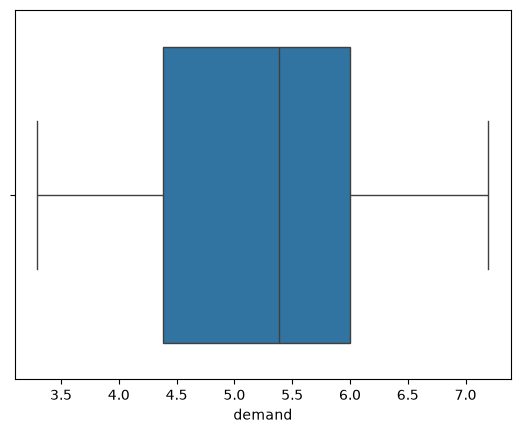

In [248]:
sns.boxplot(x=y_train_log, data=df_train)

In [249]:
poly = PolynomialFeatures(degree = 2, include_bias = False)

X_train_poly = poly.fit_transform(X_train[continuous_cols])
X_test_poly = poly.transform(X_test[continuous_cols])

poly_cols = poly.get_feature_names_out(continuous_cols)

X_train_poly = pd.DataFrame(X_train_poly, columns=poly_cols, index=X_train.index)
X_test_poly = pd.DataFrame(X_test_poly, columns=poly_cols, index=X_test.index)

In [250]:
X_train_rest = X_train.drop(columns=continuous_cols)
X_test_rest = X_test.drop(columns=continuous_cols)

In [251]:
X_train_final = pd.concat([X_train_rest, X_train_poly], axis=1)

X_test_final = pd.concat([X_test_rest, X_test_poly], axis=1)

In [252]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_final)
X_test_scaled = scaler.transform(X_test_final)

In [253]:
alphas = np.logspace(-4, 4, 60)

regcv = RidgeCV(alphas = alphas, cv = 5)
regcv.fit(X_train_scaled, y_train_log)

print("Best alpha:", regcv.alpha_)


Best alpha: 0.8554672535565685


In [254]:
y_pred_log = regcv.predict(X_test_scaled)
y_pred = np.expm1(y_pred_log)

In [255]:
r2_score(y_test, y_pred)

0.8598479806887329

In [256]:
root_mean_squared_log_error(y_test, y_pred)

0.3555573279609663

In [257]:
y_full_raw = df_train['demand']
y_full_log = np.log1p(y_full_raw)

X_full = X.copy()

poly = PolynomialFeatures(degree=2,include_bias=False)

X_full_poly = poly.fit_transform(X_full[continuous_cols])

poly_cols = poly.get_feature_names_out(continuous_cols)

X_full_poly = pd.DataFrame(X_full_poly,columns=poly_cols,index=X_full.index)

X_full_other = X_full.drop(columns=continuous_cols)

X_full_processed = pd.concat([X_full_other, X_full_poly],axis=1)

sscaler = StandardScaler()

X_full_processed[poly_cols] = sscaler.fit_transform(X_full_processed[poly_cols])

modelcv = RidgeCV(alphas=alphas,cv=5)

modelcv.fit(X_full_processed, y_full_log)
print("Best alpha:", modelcv.alpha_)

Best alpha: 0.33529241492495565


In [258]:
X_test = df_test.drop(columns=["id", "demand"], errors="ignore")
X_test = X_test.reindex(columns=X_full.columns, fill_value=0)

X_poly = pd.DataFrame(poly.transform(X_test[continuous_cols]),columns=poly_cols,index=X_test.index)

X_test = pd.concat([X_test.drop(columns=continuous_cols), X_poly],axis=1)

X_test[poly_cols] = sscaler.transform(X_test[poly_cols])

pred = np.clip(np.expm1(modelcv.predict(X_test)),0,None)

submission = pd.DataFrame({
    "id": df_test["id"],
    "demand": pred
})

submission.to_csv("submission14.csv", index=False)

In [259]:
coef = pd.Series(
    regcv.coef_,
    index=X_full_processed.columns
)

coef = coef.sort_values(key=np.abs, ascending=False)

print(coef.head(30))

feature_feel_temp                0.528113
Hour_7_Workday                   0.305499
feature_feel_temp^2             -0.292704
hour_cos                        -0.281420
Hour_8_Workday                   0.277519
hour_sin                        -0.249520
feature_humidity                 0.179005
feature_wind                     0.178408
season_code_4                    0.178179
Year_2012                        0.176097
feature_humidity^2              -0.163374
Hour_4                          -0.155698
Hour_18_Workday                  0.140607
Hour_17_Workday                  0.131588
Hour_3                          -0.129629
feature_wind^2                  -0.129205
season_code_3                    0.126548
Hour_20                          0.124325
Hour_21                          0.115993
Hour_19_Workday                  0.111424
Hour_9_Workday                   0.108100
Hour_16                          0.100161
season_code_2                    0.099238
humidity_workday                 0

In [260]:
coef.tail(20)

Day_of_Week_2                    -0.017066
Day_of_Week_6                     0.016772
Month_9                           0.014977
Month_7                          -0.014567
Month_12                         -0.014439
category_weather_2               -0.012725
Month_3                           0.012477
Day_of_Week_5                    -0.010421
Day_of_Week_4                    -0.009564
Month_2                           0.009190
Day_of_Week_3                    -0.008788
month_sin                         0.008051
Month_4                          -0.007573
feature_feel_temp feature_wind   -0.006940
wind_workday                      0.005952
Month_8                           0.005582
Hour_8                            0.004623
category_weather_4                0.003442
Month_6                           0.003039
Month_10                         -0.000437
dtype: float64

In [261]:
X_test_final.head()

,flag_holiday,flag_working,hour_sin,hour_cos,month_sin,month_cos,dow_sin,dow_cos,is_peak,is_weekend,...,humidity_workday,feature_feel_temp,feature_humidity,feature_wind,feature_feel_temp^2,feature_feel_temp feature_humidity,feature_feel_temp feature_wind,feature_humidity^2,feature_humidity feature_wind,feature_wind^2
8522,0,1,-0.866025,0.500000,-5.000000e-01,-0.866025,0.781831,0.623490,0,0,...,0.623712,0.6818,0.623712,0.323265,0.464851,0.425247,0.220402,0.389017,0.201624,0.1045
4046,1,0,0.707107,-0.707107,-8.660254e-01,0.500000,0.781831,0.623490,1,0,...,0.000000,0.3939,0.610940,0.405216,0.155157,0.240649,0.159615,0.373248,0.247563,0.1642
8297,0,0,-0.500000,0.866025,-8.660254e-01,-0.500000,0.000000,1.000000,0,1,...,0.000000,0.5606,0.453188,0.405216,0.314272,0.254057,0.227164,0.205379,0.183639,0.1642
7118,0,1,0.258819,0.965926,-2.449294e-16,1.000000,-0.433884,-0.900969,0,0,...,0.488188,0.3485,0.488188,0.150000,0.121452,0.170134,0.052275,0.238328,0.073228,0.0225
10258,0,1,-0.500000,-0.866025,1.224647e-16,-1.000000,-0.433884,-0.900969,0,0,...,0.453188,0.7879,0.453188,0.405216,0.620786,0.357067,0.319270,0.205379,0.183639,0.1642


In [262]:
X_test_final.columns

Index(['flag_holiday', 'flag_working', 'hour_sin', 'hour_cos', 'month_sin',
       'month_cos', 'dow_sin', 'dow_cos', 'is_peak', 'is_weekend',
       'rush_bad_weather', 'season_code_2', 'season_code_3', 'season_code_4',
       'category_weather_2', 'category_weather_3', 'category_weather_4',
       'Day_of_Week_1', 'Day_of_Week_2', 'Day_of_Week_3', 'Day_of_Week_4',
       'Day_of_Week_5', 'Day_of_Week_6', 'Hour_1', 'Hour_10', 'Hour_11',
       'Hour_12', 'Hour_13', 'Hour_14', 'Hour_15', 'Hour_16', 'Hour_17',
       'Hour_18', 'Hour_19', 'Hour_2', 'Hour_20', 'Hour_21', 'Hour_22',
       'Hour_23', 'Hour_3', 'Hour_4', 'Hour_5', 'Hour_6', 'Hour_7', 'Hour_8',
       'Hour_9', 'Year_2012', 'Month_10', 'Month_11', 'Month_12', 'Month_2',
       'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8',
       'Month_9', 'Hour_7_Workday', 'Hour_8_Workday', 'Hour_9_Workday',
       'Hour_17_Workday', 'Hour_18_Workday', 'Hour_19_Workday', 'wind_workday',
       'humidity_workday', 'featu